# <center> TRABALHO DE CONCLUSÃO DE CURSO </center>
## <center> Especialização em Ciência de Dados - Turma 2018.1 - Facens </center>



|**Orientador:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

Resumo:...

# 1 - Análise dos dados

Para o presente trabalho será utilizado um conjunto de datasets, sendo eles:

**Fotovoltaico.csv** - referente a dados da estação fotovoltaica composta por quatro inversores solares.

**Meteorologico.csv** - referente a dados da estação meteorológica.


In [1]:
#CÉLULA TCC-01
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter, MinuteLocator, DayLocator
from datetime import datetime
from collections import Counter

In [2]:
#CÉLULA TCC-02
#Método responsável por carregar os arquivos csv's
def loadDataFile(fileName, DateTimeIndex):
    #Convertendo a coluna de data para index e para o formato de DateTime
    if DateTimeIndex:    
        return pd.read_csv(fileName, encoding='utf-8', index_col=0, parse_dates=[0])
    else:
        return pd.read_csv(fileName, encoding='utf-8')

In [3]:
#CÉLULA TCC-03
# Método responsável por salvar o arquivo em formato csv
def saveDataFile(dataFrame, fileName):
    dataFrame.to_csv(fileName, encoding='utf-8', sep=',', index=False)

In [4]:
#CÉLULA TCC-04
#Método responsável por plotar os dataFrames
def showDataPlot(dataFrame):
    #plt.plot(dfFT.index,dfFT.energia_dia, 'ro-')
    #plt.plot(dfFT.index,dfFT.potencia, 'b+-')
    plt.grid()
    plt.plot(dataFrame)
    plt.gca().legend(dataFrame.columns)
    plt.show()

## 1.1 - Análise do dataset fotovoltaico

In [5]:
#CÉLULA TCC-0
dataSetFotoVoltaico = ['Fotovoltaico_Abr_2019.csv',
'Fotovoltaico_Ago_2018.csv',
'Fotovoltaico_Dez_2018.csv',
'Fotovoltaico_Fev_2019.csv',
'Fotovoltaico_Jan_2019.csv',
'Fotovoltaico_Jul_2018.csv',
'Fotovoltaico_Jun_2019.csv',
'Fotovoltaico_Mai_2019.csv',
'Fotovoltaico_Mar_2019.csv',
'Fotovoltaico_Nov_2018.csv',
'Fotovoltaico_Out_2018.csv',
'Fotovoltaico_Sep_2018.csv']

In [7]:
#CÉLULA TCC-0
for idx, data in  enumerate(dataSetFotoVoltaico):
    path = '{}'.format(data)
    if idx == 0:
        dfRawFoto = loadDataFile(path, True)
    else:
        dfRawFoto = pd.concat([dfRawFoto, loadDataFile(path, True)])
dfRawFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8022697 entries, 2019-04-30 23:59:57.940000 to 2018-09-01 00:00:02.713000
Data columns (total 8 columns):
painel           float64
energia_dia      float64
energia_ano      float64
energia_total    float64
potencia         float64
power_led        int64
solarnet_led     int64
solarweb_led     int64
dtypes: float64(5), int64(3)
memory usage: 550.9 MB


In [8]:
#CÉLULA TCC-
#Selecionando campos
dfRawFoto.drop({
    #'painel',#Campo representando cada inversor instalado, ou seja, 4 inversores, podendo ser 1,2,3 e 4;
    #'energia_dia',#Campo representando a energia acumulada por dia, retirado do próprio inversor (Wh);
    'energia_ano',#Campo representando a energia acumulada por ano (Wh);
    'energia_total',#Campo representando a energia acumulada desde o inicio da operação do painel (Wh);
    #'potencia', #Potência instantâneo, é a potência da associação de módulos conectados ao inversor (W);
    'power_led', #Led ...
    'solarnet_led', #Led ...
    'solarweb_led' #Led ...
    },axis=1, inplace=True)

In [9]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawFoto.dropna(inplace=True)

In [10]:
#CÉLULA TCC-
#Selecionando apenas o painel 1
dfRawFoto1 = dfRawFoto[dfRawFoto.painel == 1]

In [11]:
#CÉLULA TCC-
#Ordenando o data set pelo index, que representa o campo data
dfRawFoto1 = dfRawFoto1.sort_index()
dfRawFoto1.head()

,painel,energia_dia,potencia
data,,,
2018-07-01 00:00:06.897,1.0,45990.0,0.0
2018-07-01 00:00:10.697,1.0,45990.0,0.0
2018-07-01 00:00:28.477,1.0,45990.0,0.0
2018-07-01 00:00:48.993,1.0,45990.0,0.0
2018-07-01 00:01:07.387,1.0,45990.0,0.0


In [12]:
#CÉLULA TCC-
dfRawFoto1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1881412 entries, 2018-07-01 00:00:06.897000 to 2019-06-19 13:31:31.123000
Data columns (total 3 columns):
painel         float64
energia_dia    float64
potencia       float64
dtypes: float64(3)
memory usage: 57.4 MB


In [13]:
#CÉLULA TCC-
dfRawFoto1['energia'] = np.where(dfRawFoto1['potencia'] > 0, dfRawFoto1['energia_dia'] - dfRawFoto1['energia_dia'].shift(1), 0)

In [14]:
#CÉLULA TCC-
dfRawFoto1[dfRawFoto1 < 0] = 0

In [15]:
#CÉLULA TCC-
dfRawFoto1.drop({'energia_dia', 'potencia'},axis=1, inplace=True)

In [16]:
#CÉLULA TCC-
dfRawFoto1.fillna(0, inplace=True)

In [17]:
#CÉLULA TCC-
dfRawFoto1.isna().sum()

painel     0
energia    0
dtype: int64

In [18]:
#CÉLULA TCC- Verificando a quantidade de registros capturados por dia e aplicando um teto
qtdByDay = Counter(dfRawFoto1.index.date.astype('M8[D]'))
qtdByDay

Counter({numpy.datetime64('2018-07-01'): 5760,
         numpy.datetime64('2018-07-02'): 5746,
         numpy.datetime64('2018-07-03'): 5760,
         numpy.datetime64('2018-07-04'): 5750,
         numpy.datetime64('2018-07-05'): 5751,
         numpy.datetime64('2018-07-06'): 5760,
         numpy.datetime64('2018-07-07'): 5760,
         numpy.datetime64('2018-07-08'): 5760,
         numpy.datetime64('2018-07-09'): 5760,
         numpy.datetime64('2018-07-10'): 5760,
         numpy.datetime64('2018-07-11'): 5759,
         numpy.datetime64('2018-07-12'): 5760,
         numpy.datetime64('2018-07-13'): 5760,
         numpy.datetime64('2018-07-14'): 5760,
         numpy.datetime64('2018-07-15'): 5760,
         numpy.datetime64('2018-07-16'): 5752,
         numpy.datetime64('2018-07-17'): 5760,
         numpy.datetime64('2018-07-18'): 5751,
         numpy.datetime64('2018-07-19'): 5628,
         numpy.datetime64('2018-07-20'): 5750,
         numpy.datetime64('2018-07-21'): 5760,
         nump

In [19]:
#CÉLULA TCC- Aplicando um teto para descarte de dias com falhas em medições
court = .85  # abaixo do valor, será descartado o dia
lstDaysOut = []
for i in list(dict.fromkeys(qtdByDay.elements())): 
    if qtdByDay[i] < 5760 * court : # 5760 - 15 em 15 segundo, todal de 5760 medições por dia
        lstDaysOut.append(i.astype(datetime))
lstDaysOut

[datetime.date(2018, 9, 4),
 datetime.date(2018, 9, 5),
 datetime.date(2018, 9, 23),
 datetime.date(2018, 10, 2),
 datetime.date(2018, 10, 4),
 datetime.date(2018, 10, 22),
 datetime.date(2018, 10, 23),
 datetime.date(2018, 12, 12),
 datetime.date(2018, 12, 13),
 datetime.date(2018, 12, 21),
 datetime.date(2018, 12, 22),
 datetime.date(2018, 12, 23),
 datetime.date(2018, 12, 24),
 datetime.date(2018, 12, 27),
 datetime.date(2019, 1, 30),
 datetime.date(2019, 1, 31),
 datetime.date(2019, 2, 5),
 datetime.date(2019, 2, 8),
 datetime.date(2019, 2, 22),
 datetime.date(2019, 2, 25),
 datetime.date(2019, 2, 28),
 datetime.date(2019, 3, 3),
 datetime.date(2019, 3, 5),
 datetime.date(2019, 3, 12),
 datetime.date(2019, 3, 13),
 datetime.date(2019, 3, 14),
 datetime.date(2019, 3, 28),
 datetime.date(2019, 4, 14),
 datetime.date(2019, 4, 15),
 datetime.date(2019, 6, 19)]

In [20]:
#CÉLULA TCC- Removendo dias com medições abaixo do teto
dfRawFoto1['date'] = dfRawFoto1.index.date # coluna auxiliar
for i in lstDaysOut:# correndo todos os dias com falhas nas medições
    idx = dfRawFoto1[dfRawFoto1.date == i].index # obtendo o index
    dfRawFoto1.drop(idx, inplace=True) # removendo do dataset
dfRawFoto1.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [21]:
dfRawFoto1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1787516 entries, 2018-07-01 00:00:06.897000 to 2019-06-18 23:59:49.693000
Data columns (total 2 columns):
painel     float64
energia    float64
dtypes: float64(2)
memory usage: 40.9 MB


In [22]:
#CÉLULA TCC-
len(lstDaysOut)

30

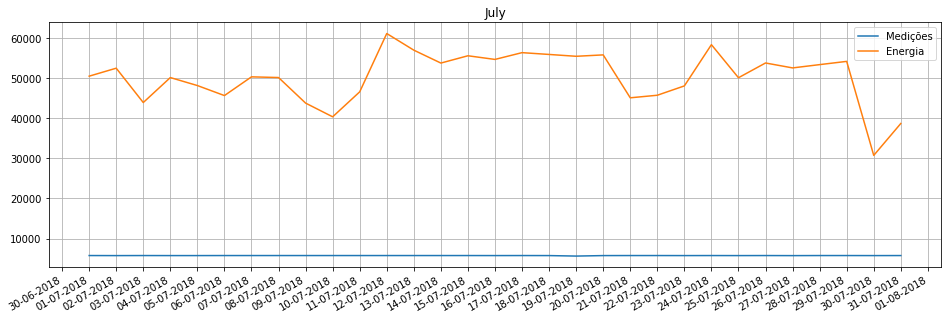

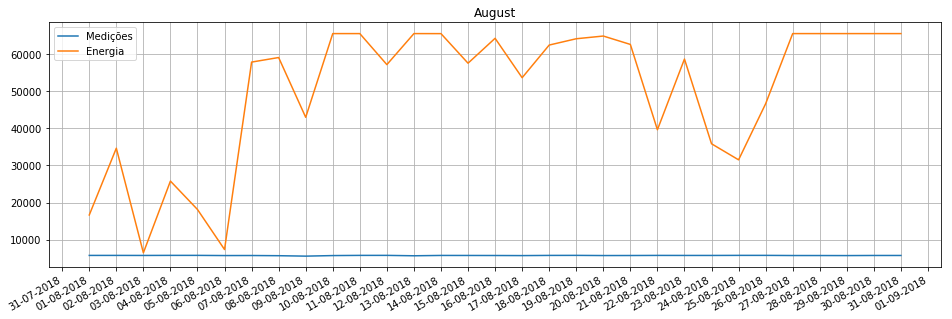

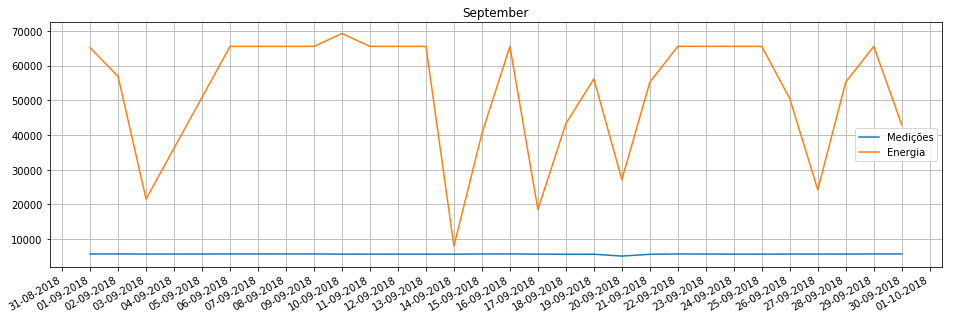

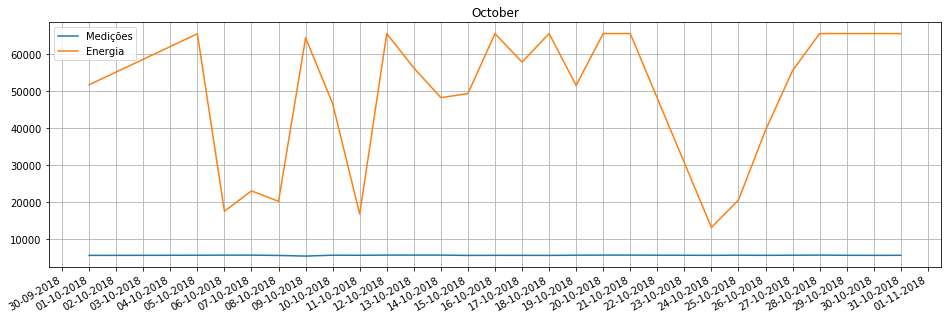

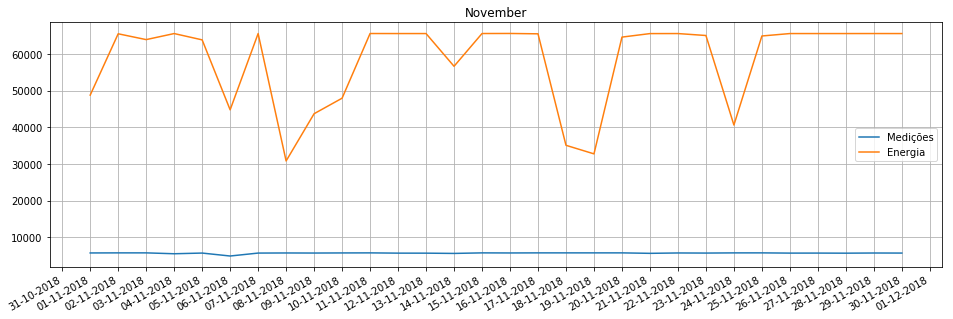

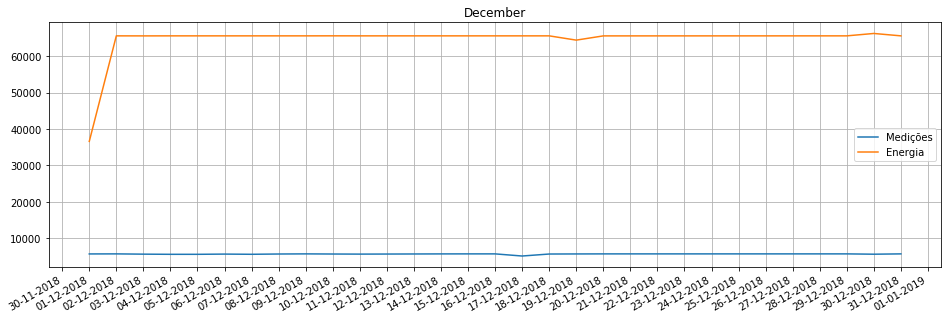

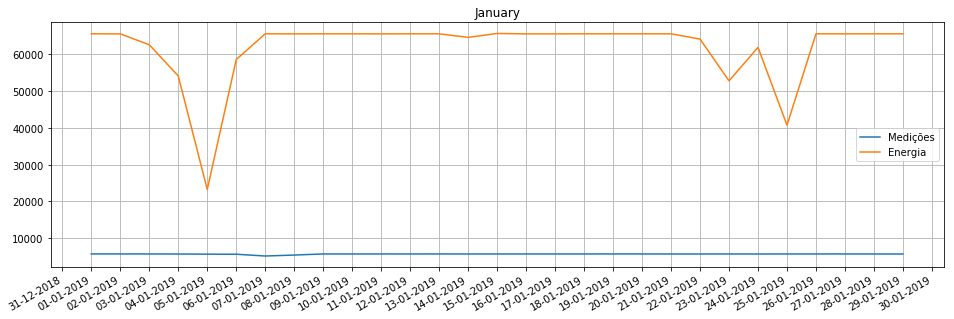

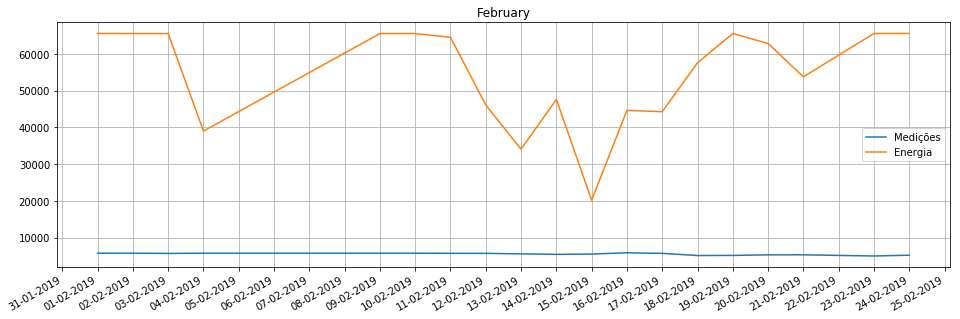

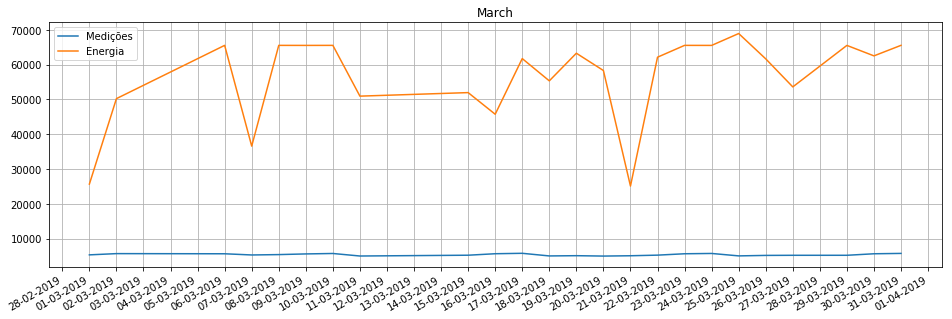

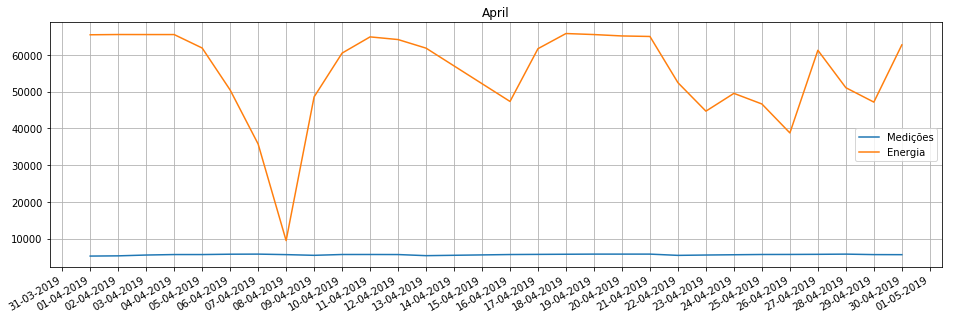

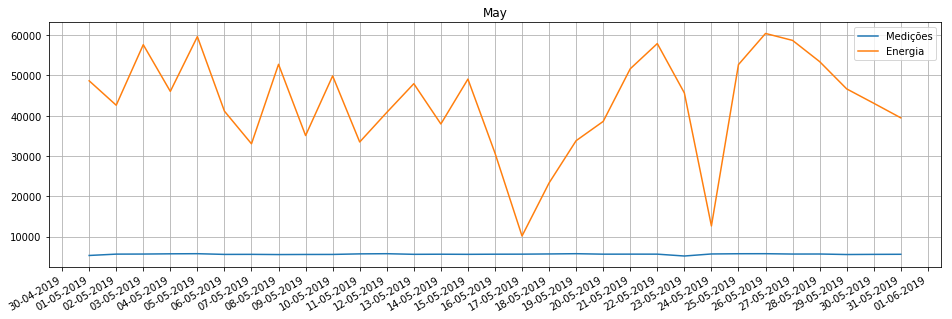

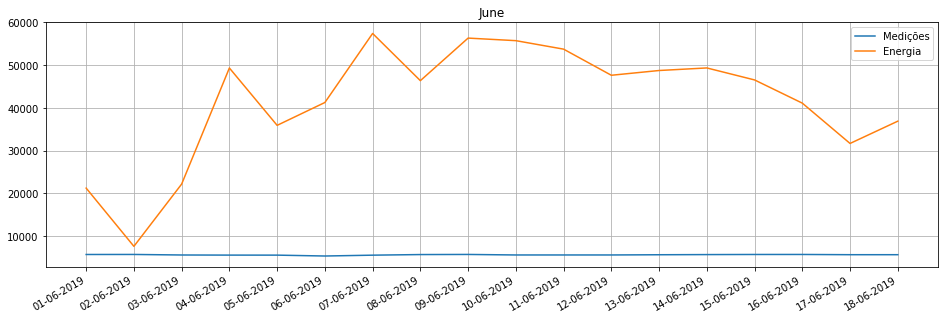

In [23]:
#CÉLULA TCC-
for m in dfRawFoto1.groupby(by=[dfRawFoto1.index.month], sort=False):
    plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1].groupby(by=[m[1].index.date]).agg({"painel":'size',"energia":'sum'}))
    #plt.plot(m[1].resample('D').agg({"painel":'size',"energia":'sum'}))
    plt.title(m[1].index.month_name()[0])
    #plt.gca().legend(m[1].columns)
    plt.gca().legend(["Medições","Energia"])
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

In [24]:
a = dfRawFoto1.reset_index()[(dfRawFoto1.reset_index()['data'] >= '2019-02-16 23:30:00') & (dfRawFoto1.reset_index()['data'] <= '2019-02-16 23:59:59') ]
a.set_index('data',inplace=True)
a.head(10)

,painel,energia
data,,
2019-02-16 23:30:06.350,1.0,0.0
2019-02-16 23:30:08.400,1.0,0.0
2019-02-16 23:30:09.900,1.0,0.0
2019-02-16 23:30:16.287,1.0,0.0
2019-02-16 23:30:27.187,1.0,0.0
2019-02-16 23:30:34.717,1.0,0.0
2019-02-16 23:30:47.877,1.0,0.0
2019-02-16 23:30:55.350,1.0,0.0
2019-02-16 23:31:06.773,1.0,0.0


In [25]:
c = dfRawFoto1.reset_index()[(dfRawFoto1.reset_index()['data'] >= '2019-02-16 00:00:00') & (dfRawFoto1.reset_index()['data'] <= '2019-02-16 23:59:59') ]
c.set_index('data',inplace=True)
c.energia.sum()

44630.0

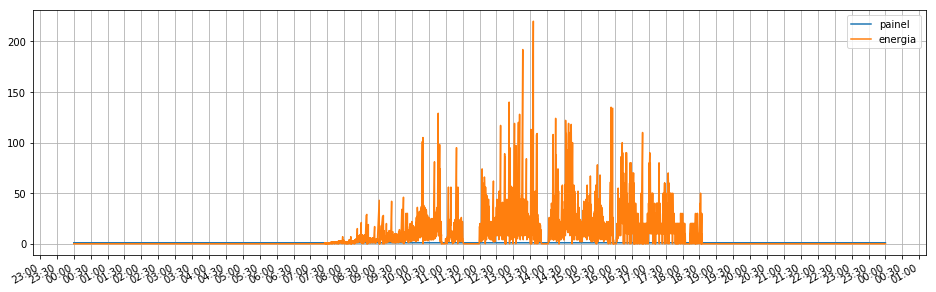

In [26]:
plt.figure(figsize=(16,5))
plt.grid()
#showDataPlot(dfRawFoto1)
##Dividir gráficos
plt.grid()
plt.plot(c)
plt.gca().legend(a.columns)
plt.gca().xaxis.set_major_locator(MinuteLocator(byminute=(0,30,0)))#DayLocator(interval=5)
plt.gca().xaxis.set_major_formatter(DateFormatter('%H:%M'))
plt.gcf().autofmt_xdate()
plt.grid()
plt.show()

## 1.2 - Análise do dataset meteorológico

In [27]:
#CÉLULA TCC-0
dataSetMeteorologico = ['Meteorologico_Abr_2019.csv',
'Meteorologico_Ago_2018.csv',
'Meteorologico_Dez_2018.csv',
'Meteorologico_Fev_2019.csv',
'Meteorologico_Jan_2019.csv',
'Meteorologico_Jul_2018.csv',
'Meteorologico_Jun_2019.csv',
'Meteorologico_Mai_2019.csv',
'Meteorologico_Mar_2019.csv',
'Meteorologico_Nov_2018.csv',
'Meteorologico_Out_2018.csv',
'Meteorologico_Sep_2018.csv']

In [29]:
#CÉLULA TCC-0
for idx, data in  enumerate(dataSetMeteorologico):
    path = '{}'.format(data)
    if idx == 0:
        dfRawMete = loadDataFile(path, True)
    else:
        dfRawMete = pd.concat([dfRawMete, loadDataFile(path, True)])
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 50502 entries, 2019-04-01 00:00:06 to 2018-09-01 00:00:06
Data columns (total 14 columns):
deficit_vapor_vmin         50502 non-null float64
deficit_vapor_vmedio       50502 non-null float64
ponto_orvalho_vmin         50502 non-null float64
ponto_orvalho_vmedio       50502 non-null float64
precipitacao_valor         50502 non-null float64
radiacao_solar_valor       50497 non-null float64
temperatura_ar_vmin        50502 non-null float64
temperatura_ar_vmedio      50502 non-null float64
temperatura_ar_vmax        50502 non-null float64
umidade_ar_vmin            50502 non-null float64
umidade_ar_vmedio          50502 non-null float64
umidade_ar_vmax            50502 non-null float64
velocidade_vento_vmedio    50502 non-null float64
velocidade_vento_vmax      50502 non-null float64
dtypes: float64(14)
memory usage: 5.8 MB


In [30]:
#CÉLULA TCC-
#Selecionando campos
dfRawMete.drop({
    #'deficit_vapor_vmin',
    #'deficit_vapor_vmedio',
    #'ponto_orvalho_vmin',
    #'ponto_orvalho_vmedio',
    #'precipitacao_valor',
    #'radiacao_solar_valor',
    #'temperatura_ar_vmin',#
    #'temperatura_ar_vmedio',
    #'temperatura_ar_vmax',#
    #'umidade_ar_vmin',#
    #'umidade_ar_vmedio',
    #'umidade_ar_vmax',#
    #'velocidade_vento_vmedio',
    #'velocidade_vento_vmax'
    },axis=1, inplace=True)

In [31]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawMete.dropna(inplace=True)

In [32]:
#CÉLULA TCC-
dfRawMete.head()

,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
data,,,,,,,,,,,,,,
2019-04-01 00:00:06,0.56,0.56,17.0,17.0,0.0,0.0,21.18,21.20,21.22,77.20,77.26,77.33,0.7,0.8
2019-04-01 00:10:07,0.57,0.57,17.1,17.1,0.0,0.0,21.25,21.25,21.25,77.35,77.35,77.35,0.8,0.8
2019-04-01 00:20:06,0.58,0.58,17.1,17.1,0.0,0.0,21.29,21.29,21.30,77.04,77.05,77.07,0.9,1.1
2019-04-01 00:30:06,0.59,0.59,17.0,17.0,0.0,0.0,21.33,21.34,21.36,76.31,76.45,76.60,0.9,1.0
2019-04-01 00:40:07,0.60,0.60,16.9,16.9,0.0,0.0,21.36,21.37,21.39,76.00,76.05,76.10,0.8,1.0


In [33]:
#CÉLULA TCC-
qtdByDayMete = Counter(dfRawMete.index.date.astype('M8[D]'))
qtdByDayMete

Counter({numpy.datetime64('2019-04-01'): 144,
         numpy.datetime64('2019-04-02'): 144,
         numpy.datetime64('2019-04-03'): 144,
         numpy.datetime64('2019-04-04'): 144,
         numpy.datetime64('2019-04-05'): 140,
         numpy.datetime64('2019-04-06'): 144,
         numpy.datetime64('2019-04-07'): 141,
         numpy.datetime64('2019-04-08'): 144,
         numpy.datetime64('2019-04-09'): 142,
         numpy.datetime64('2019-04-10'): 139,
         numpy.datetime64('2019-04-11'): 144,
         numpy.datetime64('2019-04-12'): 144,
         numpy.datetime64('2019-04-13'): 141,
         numpy.datetime64('2019-04-14'): 143,
         numpy.datetime64('2019-04-15'): 144,
         numpy.datetime64('2019-04-16'): 141,
         numpy.datetime64('2019-04-17'): 144,
         numpy.datetime64('2019-04-18'): 143,
         numpy.datetime64('2019-04-19'): 137,
         numpy.datetime64('2019-04-20'): 143,
         numpy.datetime64('2019-04-21'): 143,
         numpy.datetime64('2019-04

In [34]:
#CÉLULA TCC- Aplicando um teto para descarte de dias com falhas em medições
lstDaysOutMete = []
for i in list(dict.fromkeys(qtdByDayMete.elements())): 
    if qtdByDayMete[i] < 144 * court : # 144 - 10 em 10 minutos, todal de 144 medições por dia
        lstDaysOutMete.append(i.astype(datetime))
lstDaysOutMete

[datetime.date(2018, 8, 19),
 datetime.date(2018, 12, 1),
 datetime.date(2018, 12, 2),
 datetime.date(2018, 12, 3),
 datetime.date(2018, 12, 4),
 datetime.date(2018, 12, 5),
 datetime.date(2018, 12, 6),
 datetime.date(2018, 12, 7),
 datetime.date(2018, 12, 8),
 datetime.date(2018, 12, 10),
 datetime.date(2018, 12, 11),
 datetime.date(2018, 12, 13),
 datetime.date(2018, 12, 14),
 datetime.date(2018, 12, 15),
 datetime.date(2018, 12, 16),
 datetime.date(2018, 12, 17),
 datetime.date(2019, 2, 11),
 datetime.date(2019, 6, 25),
 datetime.date(2018, 10, 22),
 datetime.date(2018, 10, 23)]

In [35]:
#CÉLULA TCC- Removendo dias com medições abaixo do teto
dfRawMete['date'] = dfRawMete.index.date # coluna auxiliar
for i in lstDaysOutMete:# correndo todos os dias com falhas nas medições
    idx = dfRawMete[dfRawMete.date == i].index # obtendo o index
    dfRawMete.drop(idx, inplace=True) # removendo do dataset
dfRawMete.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [36]:
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48505 entries, 2019-04-01 00:00:06 to 2018-09-01 00:00:06
Data columns (total 14 columns):
deficit_vapor_vmin         48505 non-null float64
deficit_vapor_vmedio       48505 non-null float64
ponto_orvalho_vmin         48505 non-null float64
ponto_orvalho_vmedio       48505 non-null float64
precipitacao_valor         48505 non-null float64
radiacao_solar_valor       48505 non-null float64
temperatura_ar_vmin        48505 non-null float64
temperatura_ar_vmedio      48505 non-null float64
temperatura_ar_vmax        48505 non-null float64
umidade_ar_vmin            48505 non-null float64
umidade_ar_vmedio          48505 non-null float64
umidade_ar_vmax            48505 non-null float64
velocidade_vento_vmedio    48505 non-null float64
velocidade_vento_vmax      48505 non-null float64
dtypes: float64(14)
memory usage: 5.6 MB


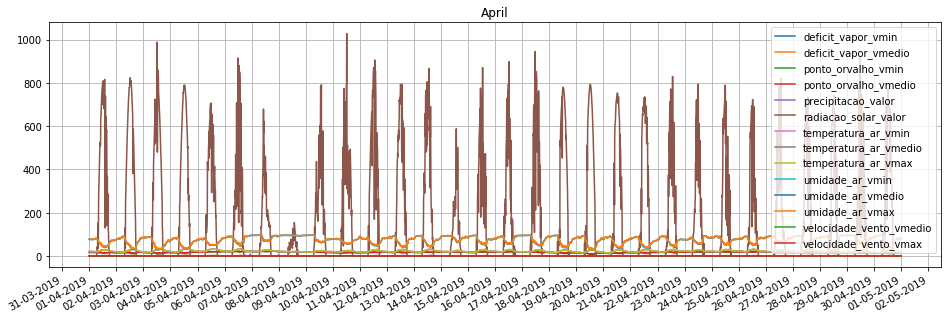

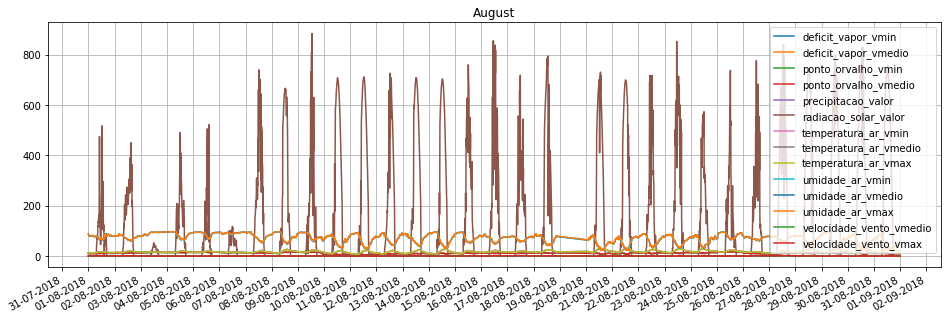

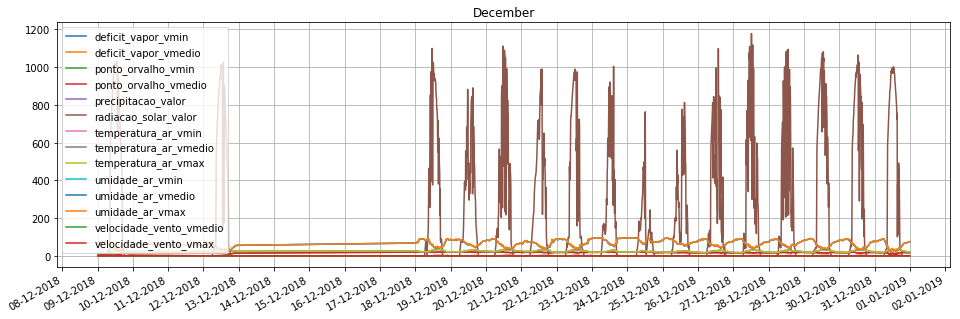

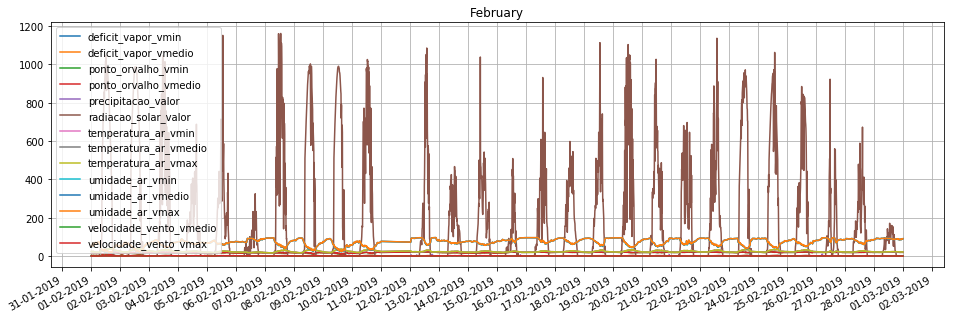

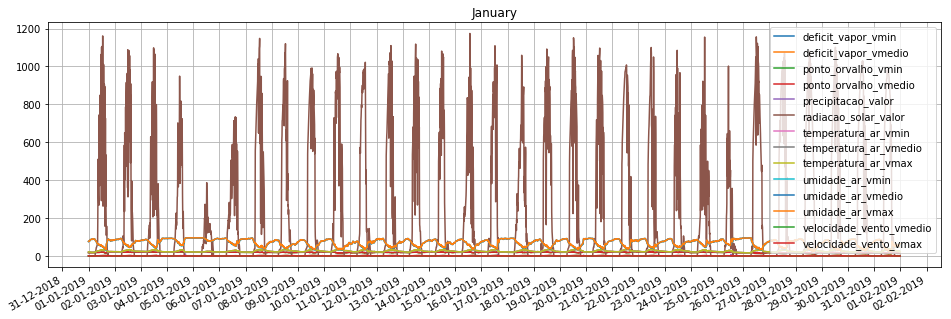

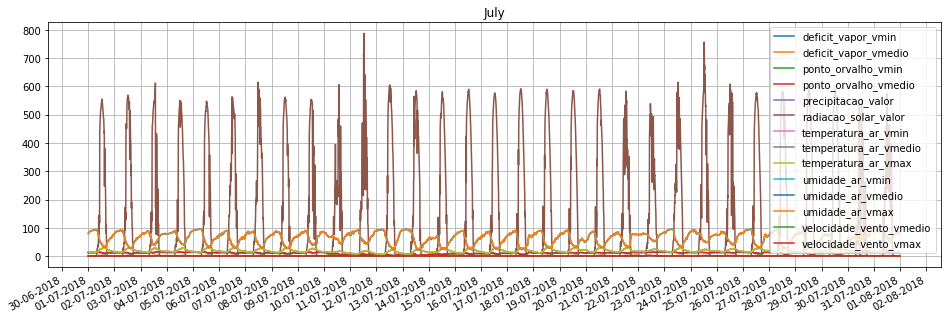

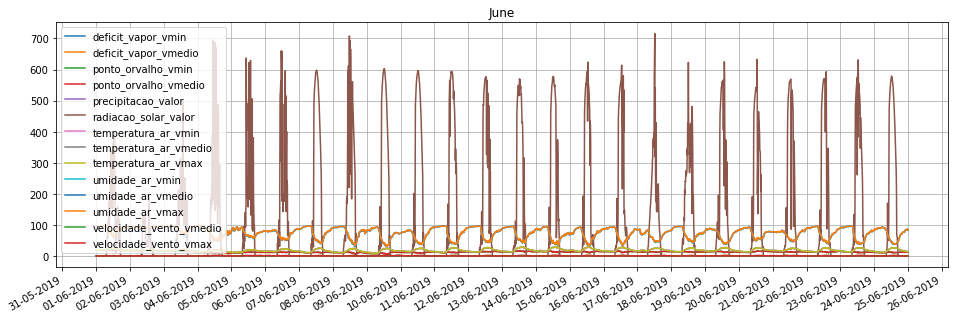

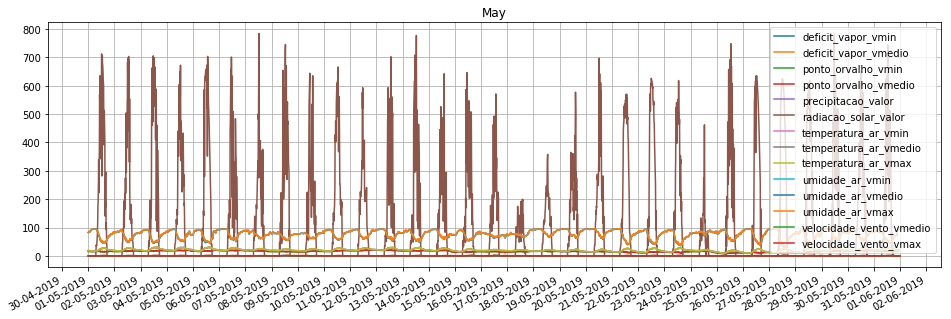

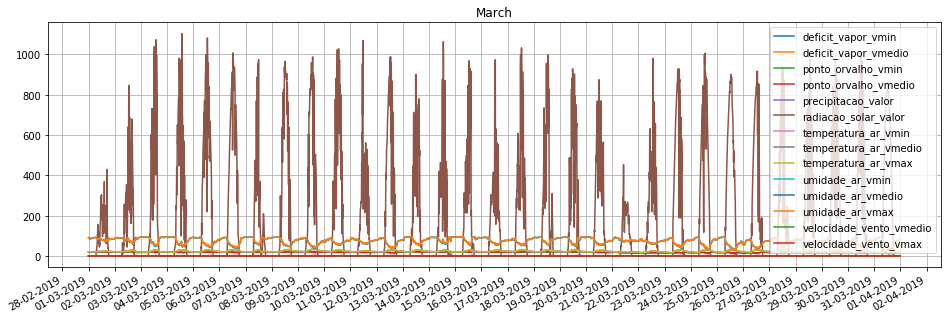

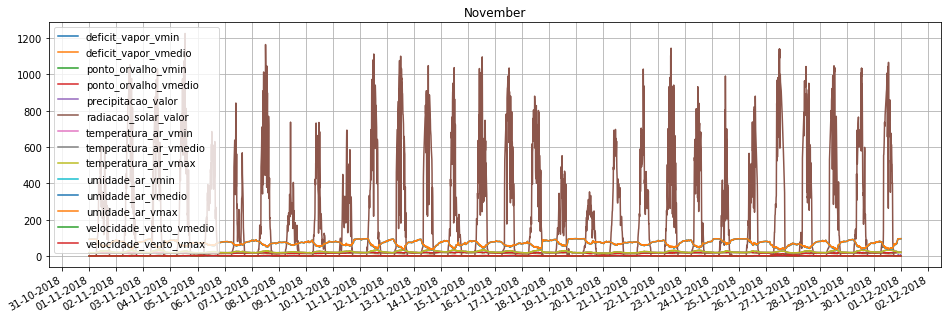

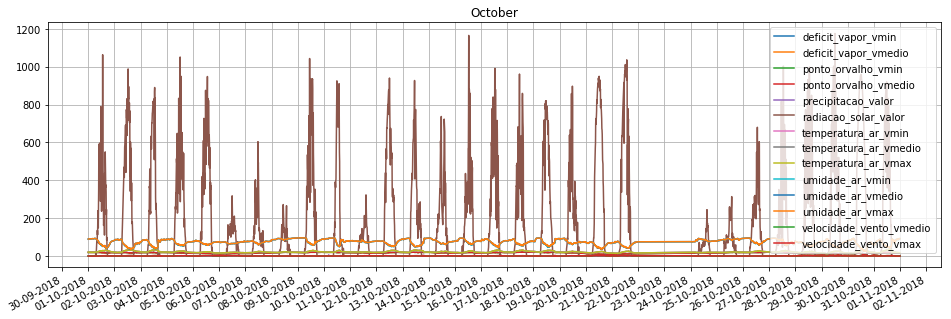

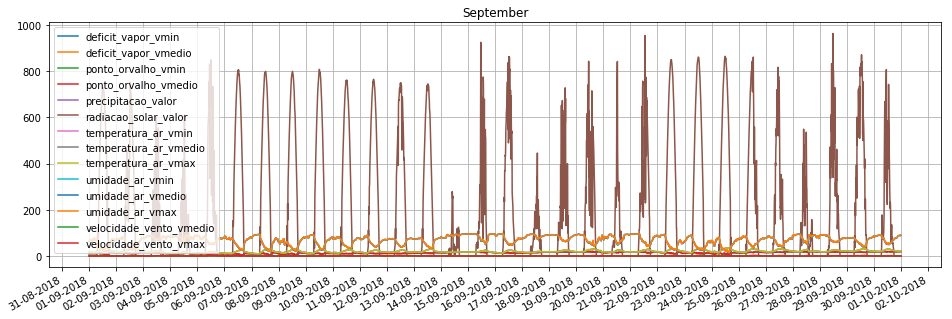

In [37]:
#CÉLULA TCC-
#showDataPlot(dfRawMete)
for m in dfRawMete.groupby(by=[dfRawMete.index.month], sort=False):
    plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1])
    #plt.plot(m[1].groupby(by=[m[1].index.date]).agg({"painel":'size',"energia":'sum'}))
    plt.title(m[1].index.month_name()[0])
    plt.gca().legend(m[1].columns)
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

## 1.3 - Unificando os datasets

Como os datasets apresentam medições distintas em tempos e frequência diferentes, como demonstra a representação abaixo:
* Fotovoltaico - apresenta em média 1 medição a cada 15 a 20 segundos, totalizando em média 240 medições por hora;
* Meteorologico - apresenta em média 1 mediação a cada 10 minutos, totalizando em média 6 medições por hora;

Será utilizado a tecnica de UpSample para os dados fotovoltaicos afim de centralizar as medições em um tempo maior, e para os dados meteorológicos a tecnica de DownSample para ajustar as medições em períodos faltantes, visando também um mesmo padrão de tempo nos dois datasets.

In [38]:
#CÉLULA TCC-
#D         calendar day frequency
#H         hourly frequency
#T, min    minutely frequency
freq = '10T' #1D - 1 dia,  10T - 10 min

## 1.3.1 - DownSample

In [39]:
dfRawFoto1.head()

,painel,energia
data,,
2018-07-01 00:00:06.897,1.0,0.0
2018-07-01 00:00:10.697,1.0,0.0
2018-07-01 00:00:28.477,1.0,0.0
2018-07-01 00:00:48.993,1.0,0.0
2018-07-01 00:01:07.387,1.0,0.0


In [40]:
#CÉLULA TCC-
downFoto = dfRawFoto1.resample(freq) #de 10 em 10 minutos cravados
newDownFoto = downFoto.agg({
    "painel":'max',
    #"potencia":'mean',
    "energia":'sum'
})
interDownFoto = newDownFoto.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
print(interDownFoto.head())

                     painel  energia
data                                
2018-07-01 00:00:00     1.0      0.0
2018-07-01 00:10:00     1.0      0.0
2018-07-01 00:20:00     1.0      0.0
2018-07-01 00:30:00     1.0      0.0
2018-07-01 00:40:00     1.0      0.0


In [41]:
interDownFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 50832 entries, 2018-07-01 00:00:00 to 2019-06-18 23:50:00
Freq: 10T
Data columns (total 2 columns):
painel     50832 non-null float64
energia    50832 non-null float64
dtypes: float64(2)
memory usage: 3.7 MB


In [42]:
#CÉLULA TCC- Removendo novamente, pois o resample gera os dias, dias com medições abaixo do teto
interDownFoto['date'] = interDownFoto.index.date # coluna auxiliar
for i in lstDaysOut:# correndo todos os dias com falhas nas medições
    idx = interDownFoto[interDownFoto.date == i].index # obtendo o index
    interDownFoto.drop(idx, inplace=True) # removendo do dataset
interDownFoto.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [43]:
interDownFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 46656 entries, 2018-07-01 00:00:00 to 2019-06-18 23:50:00
Data columns (total 2 columns):
painel     46656 non-null float64
energia    46656 non-null float64
dtypes: float64(2)
memory usage: 1.1 MB


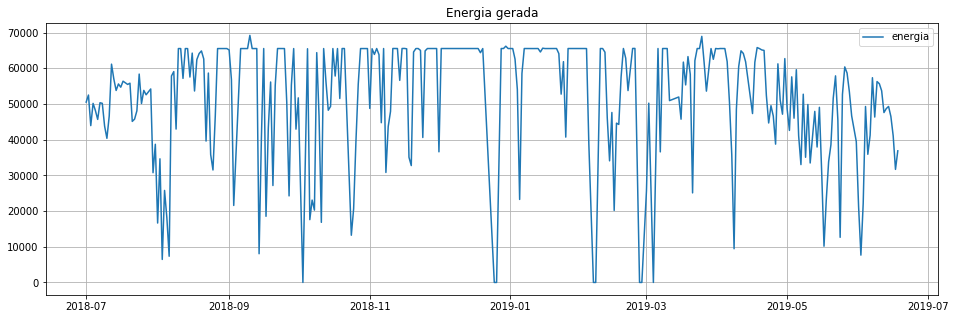

In [44]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
plt.title("Energia gerada")
showDataPlot(interDownFoto.groupby(by=interDownFoto.index.date).agg({"energia":'sum'}))
##Dividir gráficos

## 1.3.2 - UpSample

In [45]:
#CÉLULA TCC-
downMete = dfRawMete.resample(freq) #de 10 em 10 minutos cravados
newDownMete = downMete.agg({
    'deficit_vapor_vmin':'min',
    'deficit_vapor_vmedio':'mean',
    'ponto_orvalho_vmin':'min',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'radiacao_solar_valor':'mean',
    'temperatura_ar_vmin':'min',
    'temperatura_ar_vmedio':'mean',
    'temperatura_ar_vmax':'max',
    'umidade_ar_vmin':'min',
    'umidade_ar_vmedio':'mean',
    'umidade_ar_vmax':'max',
    'velocidade_vento_vmedio':'mean',
    'velocidade_vento_vmax':'max'
})
interDownMete = newDownMete.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
interDownMete.head()

,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
data,,,,,,,,,,,,,,
2018-07-01 00:00:00,0.32,0.33,11.7,11.7,0.0,0.0,15.12,15.18,15.24,79.73,80.27,80.82,0.0,0.0
2018-07-01 00:10:00,0.31,0.31,12.0,12.0,0.0,0.0,15.21,15.21,15.21,81.63,81.63,81.63,0.0,0.0
2018-07-01 00:20:00,0.32,0.32,12.0,12.0,0.0,0.0,15.17,15.18,15.19,81.42,81.43,81.44,0.0,0.0
2018-07-01 00:30:00,0.31,0.31,11.9,11.9,0.0,0.0,15.03,15.05,15.08,81.60,81.70,81.80,0.0,0.0
2018-07-01 00:40:00,0.28,0.29,11.9,11.9,0.0,0.0,14.79,14.90,15.01,82.36,82.62,82.89,0.0,0.0


In [46]:
#CÉLULA TCC
interDownMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 51696 entries, 2018-07-01 00:00:00 to 2019-06-24 23:50:00
Freq: 10T
Data columns (total 14 columns):
deficit_vapor_vmin         51696 non-null float64
deficit_vapor_vmedio       51696 non-null float64
ponto_orvalho_vmin         51696 non-null float64
ponto_orvalho_vmedio       51696 non-null float64
precipitacao_valor         51696 non-null float64
radiacao_solar_valor       51696 non-null float64
temperatura_ar_vmin        51696 non-null float64
temperatura_ar_vmedio      51696 non-null float64
temperatura_ar_vmax        51696 non-null float64
umidade_ar_vmin            51696 non-null float64
umidade_ar_vmedio          51696 non-null float64
umidade_ar_vmax            51696 non-null float64
velocidade_vento_vmedio    51696 non-null float64
velocidade_vento_vmax      51696 non-null float64
dtypes: float64(14)
memory usage: 8.4 MB


In [47]:
#CÉLULA TCC- Removendo dias com medições abaixo do teto
interDownMete['date'] = interDownMete.index.date # coluna auxiliar
for i in lstDaysOutMete:# correndo todos os dias com falhas nas medições
    idx = interDownMete[interDownMete.date == i].index # obtendo o index
    interDownMete.drop(idx, inplace=True) # removendo do dataset
interDownMete.drop(['date'], axis=1, inplace=True) # removendo coluna auxiliar

In [48]:
#CÉLULA TCC
interDownMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48960 entries, 2018-07-01 00:00:00 to 2019-06-24 23:50:00
Data columns (total 14 columns):
deficit_vapor_vmin         48960 non-null float64
deficit_vapor_vmedio       48960 non-null float64
ponto_orvalho_vmin         48960 non-null float64
ponto_orvalho_vmedio       48960 non-null float64
precipitacao_valor         48960 non-null float64
radiacao_solar_valor       48960 non-null float64
temperatura_ar_vmin        48960 non-null float64
temperatura_ar_vmedio      48960 non-null float64
temperatura_ar_vmax        48960 non-null float64
umidade_ar_vmin            48960 non-null float64
umidade_ar_vmedio          48960 non-null float64
umidade_ar_vmax            48960 non-null float64
velocidade_vento_vmedio    48960 non-null float64
velocidade_vento_vmax      48960 non-null float64
dtypes: float64(14)
memory usage: 5.6 MB


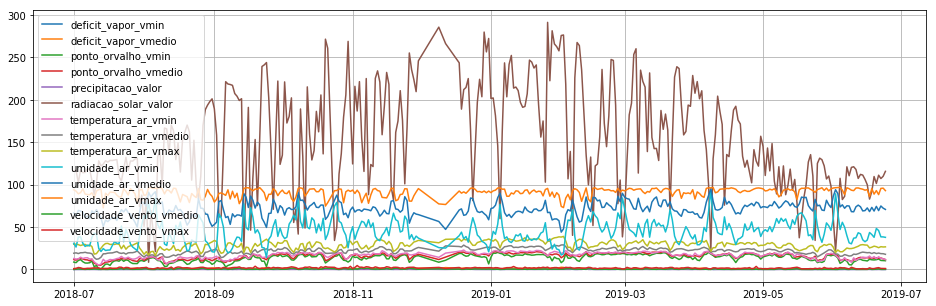

In [49]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
#showDataPlot(interDownMete)
plt.title("")
showDataPlot(interDownMete.groupby(by=interDownMete.index.date).agg({
    'deficit_vapor_vmin':'min',
    'deficit_vapor_vmedio':'mean',
    'ponto_orvalho_vmin':'min',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'radiacao_solar_valor':'mean',
    'temperatura_ar_vmin':'min',
    'temperatura_ar_vmedio':'mean',
    'temperatura_ar_vmax':'max',
    'umidade_ar_vmin':'min',
    'umidade_ar_vmedio':'mean',
    'umidade_ar_vmax':'max',
    'velocidade_vento_vmedio':'mean',
    'velocidade_vento_vmax':'max'
}))
##Dividir gráficos 

## 1.3.3 - Realizando o merge

Com os datasets padronizados na mesma freqência de medições, é possível realizar juntar ('merge') os dois em um só dataset, tornando o dataset mais interesssante por conter ambos os registros unificados. 

In [50]:
#CÉLULA TCC-
dfSet1 = pd.merge(interDownFoto, interDownMete, left_index=True, right_index=True)
#dfSet1['TotalSegundos'] = dfSet1.index.hour * 360 + dfSet1.index.minute * 60 + dfSet1.index.second
dfSet1.reset_index(inplace=True)

In [51]:
#CÉLULA TCC-
dfSet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44352 entries, 0 to 44351
Data columns (total 17 columns):
data                       44352 non-null datetime64[ns]
painel                     44352 non-null float64
energia                    44352 non-null float64
deficit_vapor_vmin         44352 non-null float64
deficit_vapor_vmedio       44352 non-null float64
ponto_orvalho_vmin         44352 non-null float64
ponto_orvalho_vmedio       44352 non-null float64
precipitacao_valor         44352 non-null float64
radiacao_solar_valor       44352 non-null float64
temperatura_ar_vmin        44352 non-null float64
temperatura_ar_vmedio      44352 non-null float64
temperatura_ar_vmax        44352 non-null float64
umidade_ar_vmin            44352 non-null float64
umidade_ar_vmedio          44352 non-null float64
umidade_ar_vmax            44352 non-null float64
velocidade_vento_vmedio    44352 non-null float64
velocidade_vento_vmax      44352 non-null float64
dtypes: datetime64[ns](1), float64

In [54]:
#CÉLULA TCC-
saveDataFile(dfSet1,'FotoMet_P1_DataSets.csv')
#saveDataFile(dfSet1,'input/FotoMet_P1_Sep_2018.csv')

In [55]:
#CÉLULA TCC-
dfSet1 = loadDataFile('FotoMet_P1_DataSets.csv', False)
#dfSet1 = loadDataFile('input/FotoMet_P1_Sep_2018.csv', False)

In [56]:
#CÉLULA TCC-
dfSet1.describe()

,painel,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
count,44352.0,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000
mean,1.0,356.009673,0.868024,0.884567,15.573904,15.656145,0.027618,152.527676,21.664712,21.759233,21.858690,70.912677,71.353613,71.799601,0.426042,0.514321
std,0.0,604.254185,0.782546,0.798869,3.739808,3.733724,0.284130,252.653467,5.136443,5.180582,5.227154,17.724684,17.505951,17.302349,0.540725,0.593095
min,1.0,0.000000,0.040000,0.040000,0.100000,0.500000,0.000000,0.000000,5.100000,5.140000,5.180000,14.180000,15.560000,15.690000,0.000000,0.000000
25%,1.0,0.000000,0.290000,0.300000,12.700000,12.800000,0.000000,0.000000,18.290000,18.350000,18.410000,58.837500,59.540000,60.230000,0.000000,0.000000
50%,1.0,0.000000,0.580000,0.590000,16.200000,16.300000,0.000000,0.000000,21.245000,21.310000,21.380000,74.300000,74.650000,75.005000,0.200000,0.300000
75%,1.0,576.000000,1.220000,1.250000,18.700000,18.700000,0.000000,218.000000,25.020000,25.140000,25.290000,85.050000,85.380000,85.780000,0.700000,0.800000
max,1.0,9297.000000,5.420000,5.440000,24.600000,24.600000,11.800000,1225.000000,38.710000,38.820000,38.940000,96.800000,96.800000,96.810000,3.700000,4.600000


In [57]:
dfSet1.head()

,data,painel,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
0,2018-07-01 00:00:00,1.0,0.0,0.32,0.33,11.7,11.7,0.0,0.0,15.12,15.18,15.24,79.73,80.27,80.82,0.0,0.0
1,2018-07-01 00:10:00,1.0,0.0,0.31,0.31,12.0,12.0,0.0,0.0,15.21,15.21,15.21,81.63,81.63,81.63,0.0,0.0
2,2018-07-01 00:20:00,1.0,0.0,0.32,0.32,12.0,12.0,0.0,0.0,15.17,15.18,15.19,81.42,81.43,81.44,0.0,0.0
3,2018-07-01 00:30:00,1.0,0.0,0.31,0.31,11.9,11.9,0.0,0.0,15.03,15.05,15.08,81.60,81.70,81.80,0.0,0.0
4,2018-07-01 00:40:00,1.0,0.0,0.28,0.29,11.9,11.9,0.0,0.0,14.79,14.90,15.01,82.36,82.62,82.89,0.0,0.0


## 2 - Normalização

Descrição ...

In [58]:
#CÉLULA TCC-
df = dfSet1.drop(['data'],axis=1)

In [59]:
#CÉLULA TCC-
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler()
df[df.columns] = min_max_scaler.fit_transform(df[df.columns])
df.describe()

,painel,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
count,44352.0,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000,44352.000000
mean,0.0,0.038293,0.153908,0.156401,0.631588,0.628886,0.002340,0.124512,0.492851,0.493445,0.494037,0.686670,0.686775,0.691686,0.115146,0.111809
std,0.0,0.064995,0.145455,0.147939,0.152645,0.154926,0.024079,0.206248,0.152825,0.153818,0.154833,0.214533,0.215484,0.213293,0.146142,0.128934
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,0.046468,0.048148,0.514286,0.510373,0.000000,0.000000,0.392443,0.392221,0.391884,0.540517,0.541359,0.549063,0.000000,0.000000
50%,0.0,0.000000,0.100372,0.101852,0.657143,0.655602,0.000000,0.000000,0.480363,0.480107,0.479858,0.727669,0.727351,0.731201,0.054054,0.065217
75%,0.0,0.061955,0.219331,0.224074,0.759184,0.755187,0.000000,0.177959,0.592681,0.593824,0.595675,0.857783,0.859429,0.864029,0.189189,0.173913
max,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [60]:
#from sklearn.preprocessing import StandardScaler
#scaler = StandardScaler()
#df[df.columns] = scaler.fit_transform(df[df.columns])
#df.describe()

## 3 - Treinamento do modelo

Descrição ...

In [61]:
#CÉLULA TCC-
import seaborn as sns

from sklearn import model_selection
from sklearn import linear_model
from sklearn.ensemble import RandomForestRegressor

from sklearn import metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [62]:
#CÉLULA TCC-
def showPairPlot(dataFrame):

    pairPlot = sns.pairplot(
        dataFrame,
        size=2.0,
        aspect=1.4,
        plot_kws=dict(edgecolor="k", linewidth=0.2),
        diag_kws=dict(shade=True),        
        diag_kind="kde",
    )               
                 
    fig = pairPlot.fig
    fig.subplots_adjust(top=0.95)
    fig.suptitle(
        'Análise de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [63]:
#CÉLULA TCC-
def showHeatMap(dataFrame):
    
    fig, (ax) = plt.subplots(1, 1, figsize=(11,7))
    heatMap = sns.heatmap(
        dataFrame.corr(), 
        ax=ax,           
        cmap="coolwarm",
        annot=True, 
        fmt='.2f',
        linewidths=.07
    )

    fig.suptitle(
        'Correlação de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [64]:
#CÉLULA TCC-
def showResultPlot(y_pred,y_test):
    plt.figure(figsize=(17,7))
    y_pred = y_pred.T

    plt.plot(range(len(y_pred)), y_pred, 'ro-')
    plt.plot(range(len(y_test)), y_test, 'b+-')
    plt.gca().legend(('Previsão','Real'))
    #plt.xticks(range(0,1150,50))
    plt.grid()
    plt.show()

In [65]:
#CÉLULA TCC-
def showResult(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)
    y_pred_Train = model.predict(X_train)
    y_pred_Test = model.predict(X_test)

    #print(model)# exibição dos parametros utilizados no modelo
    print('------------------- TREINO -------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_train, y_pred_Train)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_train, y_pred_Train))))
    #print('r²: {:.2f} %'.format(model.score(X_train, y_train) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_train, y_pred_Train) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_train, y_pred_Train)))
    print('------------------- TESTE ---------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_test, y_pred_Test)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred_Test))))
    #print('r²: {:.2f} %'.format(model.score(X_test, y_test) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_test, y_pred_Test) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_test, y_pred_Test)))

    print('----------------------------------------------------')
    showResultPlot(y_pred_Test,y_test)
    return model

In [66]:
#CÉLULA TCC-
dfParameters = df.drop([
    'painel',
    #'potencia',#
    #'energia',#
    #'deficit_vapor_vmin',#
    #'deficit_vapor_vmedio',#
    'ponto_orvalho_vmin',
    'ponto_orvalho_vmedio',
    'precipitacao_valor',
    #'radiacao_solar_valor',
    #'temperatura_ar_vmin',#
    'temperatura_ar_vmedio',
    #'temperatura_ar_vmax',#
    #'umidade_ar_vmin',#
    'umidade_ar_vmedio',
    #'umidade_ar_vmax',#
    'velocidade_vento_vmedio',
    'velocidade_vento_vmax'
    ],axis=1)

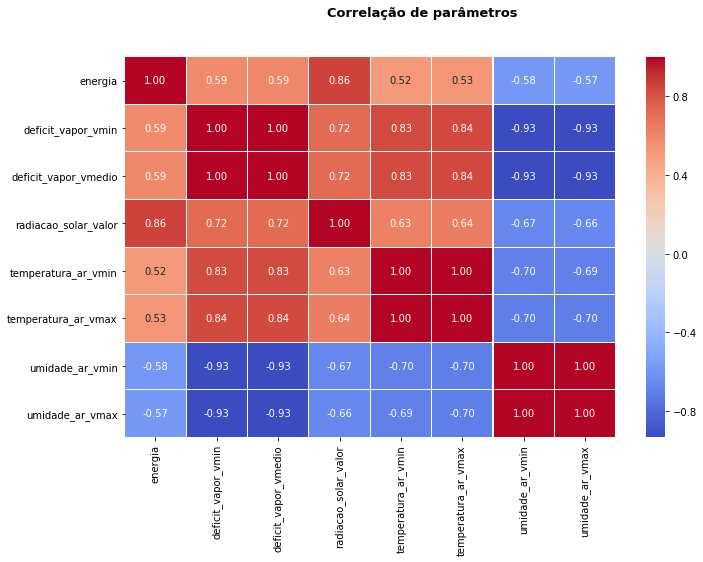

In [67]:
#CÉLULA TCC-
showHeatMap(dfParameters)

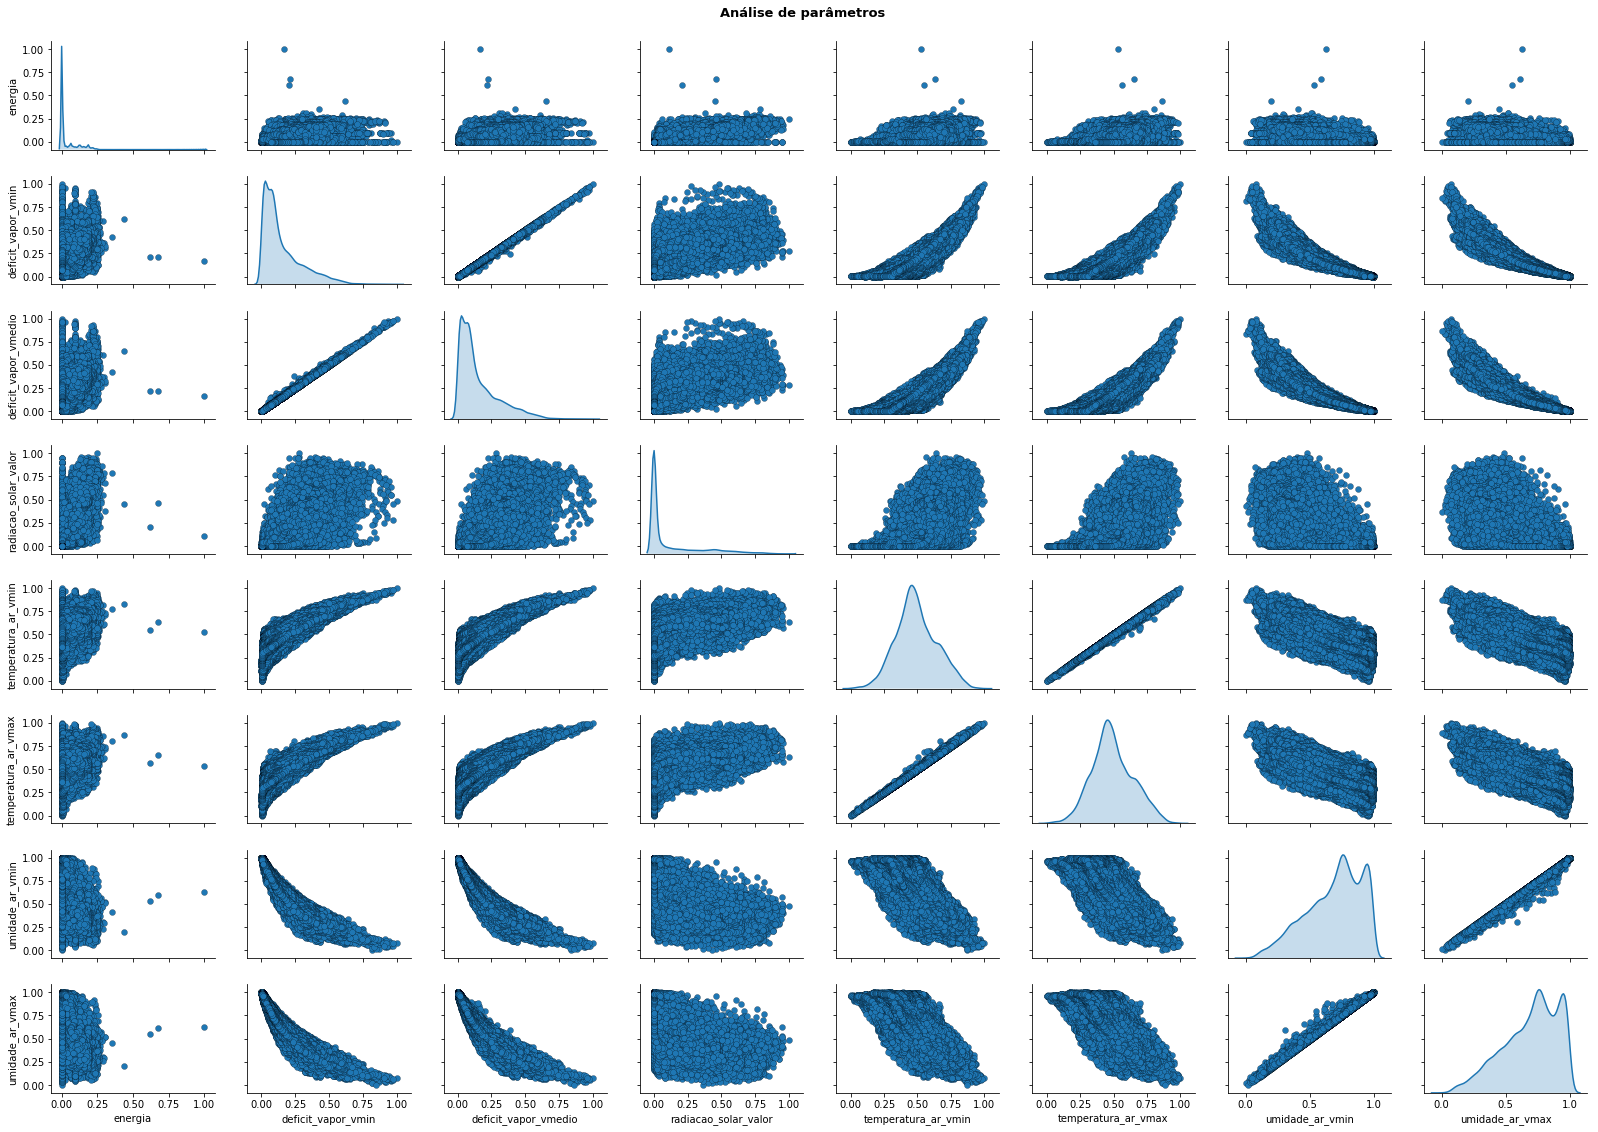

In [68]:
#CÉLULA TCC-
showPairPlot(dfParameters)

In [69]:
#CÉLULA TCC-
X = dfParameters.drop(['energia'],axis=1)
y = dfParameters.energia

In [70]:
#CÉLULA TCC-
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.25, random_state=42)

In [71]:
#CÉLULA TCC-
print(X_train.shape)
print(y_train.shape)

(33264, 7)
(33264,)


In [72]:
#CÉLULA TCC-
print(X_test.shape)
print(y_test.shape)

(11088, 7)
(11088,)


Regressão  Linear

https://towardsdatascience.com/linear-regression-in-python-9a1f5f000606

https://www.dataquest.io/blog/understanding-regression-error-metrics/

https://realpython.com/linear-regression-in-python/

https://www.analyticsvidhya.com/blog/2017/06/a-comprehensive-guide-for-linear-ridge-and-lasso-regression/

https://jovianlin.io/data-visualization-seaborn-part-2/

----------------------------------------------------
----------      REGRESSÃO LINEAR       -------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.001014
RMSE: 0.031838
r²: 76.03 %
MAE: 0.017635
------------------- TESTE ---------------------------
MSE: 0.001045
RMSE: 0.032320
r²: 75.18 %
MAE: 0.017734
----------------------------------------------------


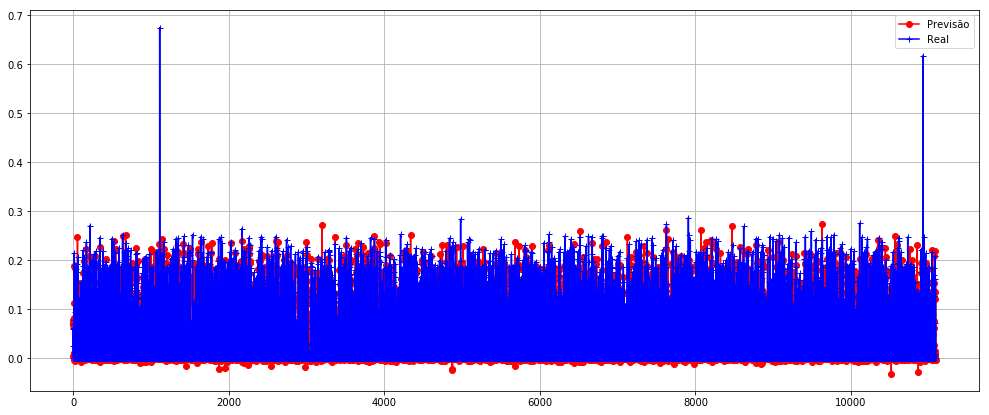

                      0  Coeficiente estimado
0    deficit_vapor_vmin              0.435735
4   temperatura_ar_vmax              0.374255
2  radiacao_solar_valor              0.282934
6       umidade_ar_vmax              0.067966
5       umidade_ar_vmin             -0.155293
3   temperatura_ar_vmin             -0.347146
1  deficit_vapor_vmedio             -0.600012


In [73]:
#CÉLULA TCC-
LinearRegression = linear_model.LinearRegression()

print('----------------------------------------------------')
print('----------      REGRESSÃO LINEAR       -------------')
print('----------------------------------------------------')
modelLinearRegression = showResult(LinearRegression, X_train, y_train, X_test, y_test)
#print(model.intercept_)
coeff = pd.DataFrame(X_train.columns)
coeff['Coeficiente estimado'] = pd.Series(modelLinearRegression.coef_)
coeff.sort_values(by='Coeficiente estimado', inplace=True, ascending=False)
print(coeff)
#print(modelRegLinear.coef_)
#for idx, col_name in enumerate(X_train.columns):
#    print("Ccoeficiente para a coluna '{}': {:.6f}".format(col_name, model.coef_[idx]))


Random Forest Regressor

----------------------------------------------------
------------      RANDOM FOREST     ----------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.000120
RMSE: 0.010961
r²: 97.16 %
MAE: 0.005129
------------------- TESTE ---------------------------
MSE: 0.000927
RMSE: 0.030448
r²: 77.97 %
MAE: 0.014151
----------------------------------------------------


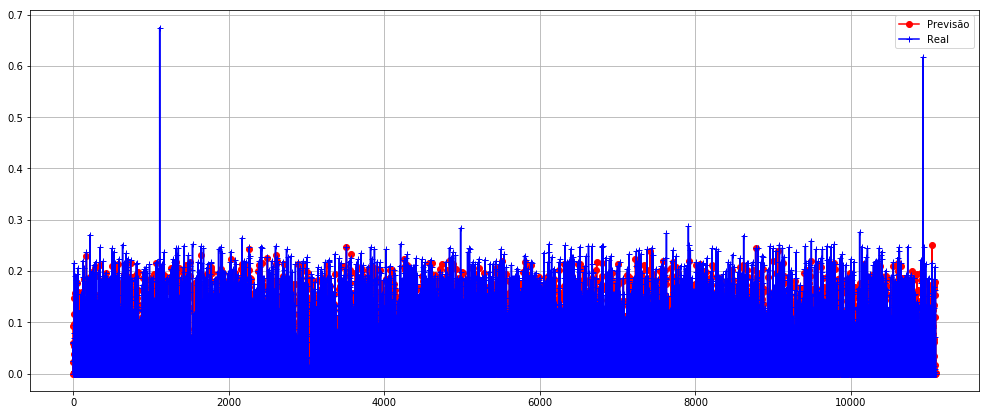

In [74]:
#CÉLULA TCC-
RandomForest = RandomForestRegressor(n_estimators=350, random_state=0)
    
print('----------------------------------------------------')
print('------------      RANDOM FOREST     ----------------')
print('----------------------------------------------------')

modelRandomForest = showResult(RandomForest, X_train, y_train, X_test, y_test)

In [75]:
#MAE é a média da diferença absoluta entre os valores previstos e o valor observado

#O numerador é MSE (média dos quadrados dos residuais) e o denominador é a variância nos valores Y. Quanto mais alto o MSE, menor o R_squared e mais pobre é o modelo.

#Por que você deve escolher R² Ajustado sobre R²?
#Existem alguns problemas com o R² normal que são resolvidos pelo R² Ajustado. Um R² ajustado considerará a melhoria marginal adicionada por um termo adicional em seu modelo. Por isso, aumentará se você adicionar os termos úteis e diminuirá se você adicionar preditores menos úteis. No entanto, o R² aumenta com termos crescentes, mesmo que o modelo não esteja realmente melhorando.

#O R², também chamado de Coeficiente de Determinação, diz o quanto meu modelo está prevendo corretamente.

#RMSE (Root Mean Square Error)(Erro Quadrado Médio da Raiz)
#Representa o desvio padrão da amostra das diferenças entre os valores previstos e os valores observados (chamados resíduos)

In [248]:
#Teste F de Significância global: afirma se ao menos uma variável do meu modelo está relacionada com a variável alvo. Para isso, o valor-p desta estatística precisa ser menor que 0.05

#Teste de Significância individuais ou p-values dos coeficientes: diz o quanto das variáveis preditoras explicam a variável alvo. A métrica padrão é o p-value ser menor que 0.05.

#Coeficiente R²: diz o quanto o meu modelo explica seus resultados. É um valor entre 0 e 1. Quanto mais próximo de 1, melhor.

## 4 - Otimização

## 5 - Resultados

# Rede LSTM

In [72]:
#CÉLULA KE-LIB-01
import numpy as np
import keras as K
import tensorflow as tf
import pandas as pd
import os
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'

In [73]:
#CÉLULA KE-LIB-02
np.random.seed(1)
tf.set_random_seed(1)

In [74]:
dfSet1 = pd.read_csv('FotoMet_P1_DataSets.csv')
dfSet1.head()

,data,painel,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
0,2018-07-01 00:00:00,1.0,0.0,0.32,0.33,11.7,11.7,0.0,0.0,15.12,15.18,15.24,79.73,80.27,80.82,0.0,0.0
1,2018-07-01 00:10:00,1.0,0.0,0.31,0.31,12.0,12.0,0.0,0.0,15.21,15.21,15.21,81.63,81.63,81.63,0.0,0.0
2,2018-07-01 00:20:00,1.0,0.0,0.32,0.32,12.0,12.0,0.0,0.0,15.17,15.18,15.19,81.42,81.43,81.44,0.0,0.0
3,2018-07-01 00:30:00,1.0,0.0,0.31,0.31,11.9,11.9,0.0,0.0,15.03,15.05,15.08,81.60,81.70,81.80,0.0,0.0
4,2018-07-01 00:40:00,1.0,0.0,0.28,0.29,11.9,11.9,0.0,0.0,14.79,14.90,15.01,82.36,82.62,82.89,0.0,0.0


In [75]:
dfSet1.isna().sum()

data                       0
painel                     0
energia                    0
deficit_vapor_vmin         0
deficit_vapor_vmedio       0
ponto_orvalho_vmin         0
ponto_orvalho_vmedio       0
precipitacao_valor         0
radiacao_solar_valor       0
temperatura_ar_vmin        0
temperatura_ar_vmedio      0
temperatura_ar_vmax        0
umidade_ar_vmin            0
umidade_ar_vmedio          0
umidade_ar_vmax            0
velocidade_vento_vmedio    0
velocidade_vento_vmax      0
dtype: int64

In [76]:
dfSet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44352 entries, 0 to 44351
Data columns (total 17 columns):
data                       44352 non-null object
painel                     44352 non-null float64
energia                    44352 non-null float64
deficit_vapor_vmin         44352 non-null float64
deficit_vapor_vmedio       44352 non-null float64
ponto_orvalho_vmin         44352 non-null float64
ponto_orvalho_vmedio       44352 non-null float64
precipitacao_valor         44352 non-null float64
radiacao_solar_valor       44352 non-null float64
temperatura_ar_vmin        44352 non-null float64
temperatura_ar_vmedio      44352 non-null float64
temperatura_ar_vmax        44352 non-null float64
umidade_ar_vmin            44352 non-null float64
umidade_ar_vmedio          44352 non-null float64
umidade_ar_vmax            44352 non-null float64
velocidade_vento_vmedio    44352 non-null float64
velocidade_vento_vmax      44352 non-null float64
dtypes: float64(16), object(1)
memory usag

data
2018-07-01 00:00:00    0.0
2018-07-01 00:10:00    0.0
2018-07-01 00:20:00    0.0
2018-07-01 00:30:00    0.0
2018-07-01 00:40:00    0.0
Name: energia, dtype: float64


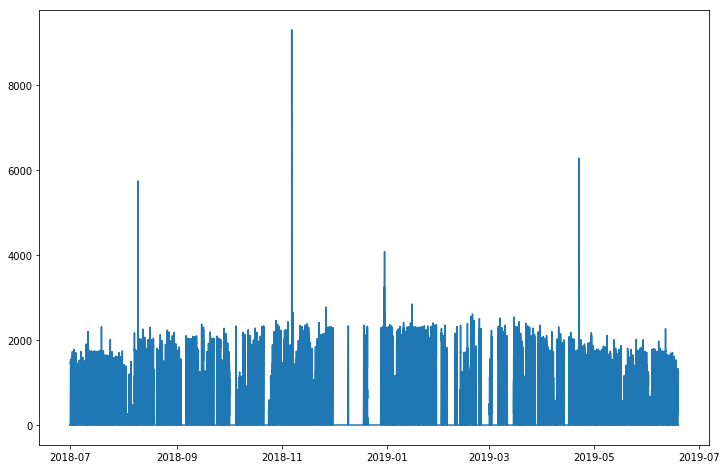

In [77]:
dfSet1['data'] = pd.to_datetime(dfSet1['data'])
dfSet1.set_index('data',inplace=True)
#keep only the 'energia' column
#enerValues = dfSet1[['energia','radiacao_solar_valor']]
enerValues = dfSet1['energia']
print(enerValues.head())

plt.figure(figsize=(12,8))
plt.plot(enerValues)
plt.show()

In [78]:
from sklearn.preprocessing import MinMaxScaler

In [79]:
enerValues = enerValues.values.reshape(enerValues.shape[0],1)
enerValues[:5]

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.]])

In [80]:
enerValues.shape

(44352, 1)

In [81]:
scaler = MinMaxScaler(feature_range=(0,1))
scaler = scaler.fit(enerValues)
enerValuesScaled = scaler.transform(enerValues)
enerValuesScaled[:5]

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.]])

In [82]:
from sklearn.model_selection import train_test_split
time_steps = 144
prediction = 1 #valor a ser previsto (10 minutos a frente)
num_features = 1 # numero de atributos usados

In [83]:
X = enerValuesScaled[0:(len(enerValuesScaled) - (len(enerValuesScaled) % time_steps))] #DADOS NORMALIZADOS
X_train = X.reshape(-1, time_steps, num_features) #Esta formatação é necessária para o LSTM 


#Valores de Saída: aqui a saída é composta por apenas 1 valor (1 label previsto após a exibição da sequencia de 1 dia)
y_train = X_train[1:, 0, 0]
y_train  = np.append(y_train, enerValuesScaled[1230])#
y_train = y_train.reshape(-1, 1)
print(y_train.shape)

#Conjunto de validação com os dados remanescentes do dataset
remain = len(enerValuesScaled) - len(X)#
X_aux = enerValuesScaled[ - remain - time_steps :]#

#o -1 é para não incluir a ultima linha porque nao sabemos o valor de saída neste caso
y_val = []
y_test_val = []
for start in range(len(X_aux) - time_steps + prediction - 1) : 
    row = X_aux[start:time_steps + start]
    y_val.append(row)
    y_test_val.append(X_aux[time_steps + start])

y_val = np.array(y_val)
y_test_val = np.array(y_test_val)

#AS variáveis X_train e y_train contém os dados uteis formatados conforme o subitem 1. Vamos dividir parte deste array para testes
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, test_size = 0.2, random_state = 0, shuffle=False)

(308, 1)


In [84]:
X_test.shape

(62, 144, 1)

In [85]:
#CÉLULA KE-LIB-10
#Montando a rede recorrente 'LSTM-Dense'
RS_VALUE = False
batch_size = 1

#Limpa o modelo previamente usado, senão irá acumular camadas
K.backend.clear_session()

tf.logging.set_verbosity(tf.logging.ERROR) #desliga os warnings do tensorflow

init   = K.initializers.glorot_uniform(seed=1)

#IMPLEMENTE O CÓDIGO AQUI

theOptimizer = K.optimizers.Adam()

model = K.models.Sequential()
model.add(K.layers.LSTM(units=15, return_sequences=RS_VALUE, batch_input_shape=(batch_size, time_steps, prediction), kernel_initializer=init, dropout=0.2, activation='relu')) 
model.add(K.layers.Dense(units=1, kernel_initializer=init, activation='tanh')) #DADOS NORMALIZADOS
#model.add(K.layers.Dense(units=1, kernel_initializer=init, activation=None)) #DADOS NÃO NORMALIZADOS


# Compile o modelo - IMPLEMENTE O CÓDIGO AQUI
model.compile(loss='mean_squared_error', optimizer=theOptimizer, metrics=['mae', 'mse'])
model.summary()

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lstm_1 (LSTM)                (1, 15)                   1020      
_________________________________________________________________
dense_1 (Dense)              (1, 1)                    16        
Total params: 1,036
Trainable params: 1,036
Non-trainable params: 0
_________________________________________________________________


In [61]:
#CÉLULA KE-LIB-11
#Treinamento
#IMPLEMENTE O CÓDIGO AQUI
max_epochs = 1
print("Iniciando treinamento... ")
h = model.fit(X_train,y_train,batch_size=batch_size, epochs=max_epochs, shuffle=False, verbose=1)
print("Treinamento finalizado \n")

Iniciando treinamento... 
Epoch 1/1
246/246 [==============================] - 90s 366ms/step - loss: 1.9617e-08 - mean_absolute_error: 4.5573e-05 - mean_squared_error: 1.9617e-08
Treinamento finalizado 



In [19]:
#CÉLULA KE-LIB-12
# Avaliação do modelo
#IMPLEMENTE O CÓDIGO AQUI
eval = model.evaluate(X_test,y_test,verbose=0)
print("Dados de teste: loss = %0.6f MAE = %0.2f%% \n" \
% (eval[0], eval[1]*100) )

Dados de teste: loss = 0.000390 MAE = 0.25% 



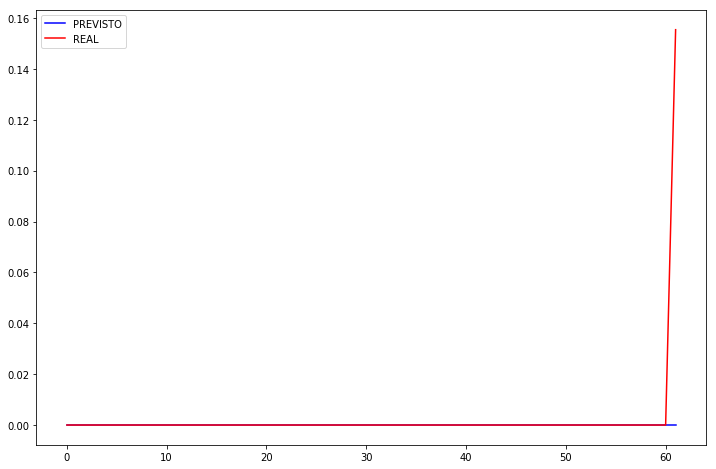

In [20]:
#CÉLULA KE-LIB-14
#Este trecho de código realiza a previsão dos valores de teste e plota o gráfico correspondente
y_pred_list = []
for i in range(len(X_test)) :
    X_data = X_test[i].reshape(1,144,1)
    y_pred = model.predict(X_data)
    y_pred_list.append(y_pred)
    
y_p = np.array(y_pred_list).ravel() #este comando faz o 'flatten' do array para que possa ser colocado no gráfico
y_t = np.array(y_test).ravel()

plt.figure(figsize=(12,8))
plt.plot(y_p, 'b', label='PREVISTO')
plt.plot(y_t, 'r', label='REAL')
plt.legend(loc='best')
plt.show()

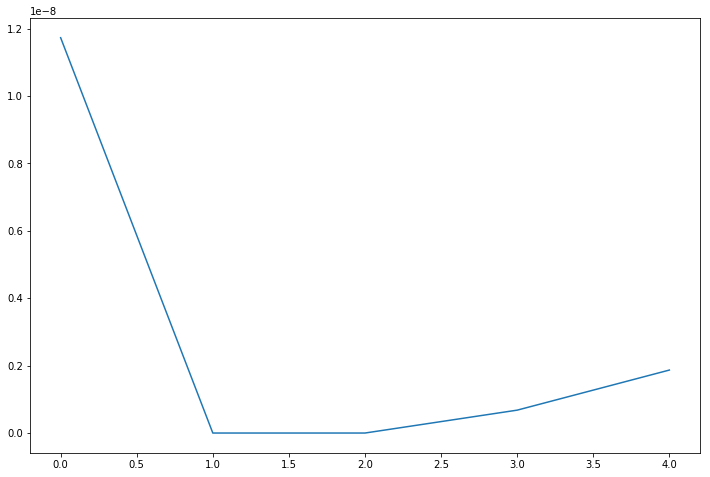

In [21]:
#Gráfico ERRO
plt.figure(figsize=(12,8))
plt.plot(range(len(h.history['loss'])), h.history['loss'])
plt.show()

In [22]:
X_test.shape

(62, 144, 1)